# TSR KPI Explorer — AV Portfolio

Exploratory analysis of the Traffic Sign Recognition evaluation output:

- `data/processed/results.parquet` — 5M frames with per-frame KPI flags (TP/TN/FP/FN/critical),
- `data/outputs/redash_db.sqlite` — aggregated BI report (`kpi_report` table).

Run the pipeline first: `uv run python demo_run.py`.

Definitions of all KPIs: see `docs/kpi-definition.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

ROOT = Path("..").resolve()
FIGURES_DIR = ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {0: "NONE", 1: "STOP", 2: "YIELD", 3: "SPEED_LIMIT", 4: "OTHER"}
WEATHER_NAMES = {0: "SUNNY", 1: "RAIN", 2: "FOG"}

## 1. Dataset overview

In [2]:
df = pl.read_parquet(ROOT / "data/processed/results.parquet")
df.shape

(5000000, 11)

In [3]:
(
    df.group_by("actual_class")
    .len(name="frames")
    .sort("actual_class")
    .with_columns(
        pl.col("actual_class").replace_strict(CLASS_NAMES, return_dtype=pl.Utf8).alias("class_name")
    )
    .select("actual_class", "class_name", "frames")
    .with_columns((pl.col("frames") / pl.col("frames").sum()).round(4).alias("share"))
)

actual_class,class_name,frames,share
i64,str,u32,f64
0,"""NONE""",2501761,0.5004
1,"""STOP""",249672,0.0499
2,"""YIELD""",249685,0.0499
3,"""SPEED_LIMIT""",1749179,0.3498
4,"""OTHER""",249703,0.0499


## 2. Overall KPI summary

Flags already include the *effective prediction* semantics: predictions with
`confidence < 0.7` are treated as NONE (`CONFIDENCE_THRESHOLD` in
`src/av_portfolio/assets/metrics.py`).

In [4]:
totals = df.select(
    pl.col("is_true_positive").sum().alias("tp"),
    pl.col("is_true_negative").sum().alias("tn"),
    pl.col("is_false_positive").sum().alias("fp"),
    pl.col("is_false_negative").sum().alias("fn"),
    pl.col("is_critical_failure").sum().alias("critical"),
)
tp = totals["tp"].item()
fp = totals["fp"].item()
fn = totals["fn"].item()

{
    "frames": df.height,
    "tp": tp,
    "tn": totals["tn"].item(),
    "fp": fp,
    "fn": fn,
    "critical_failures": totals["critical"].item(),
    "precision": round(tp / (tp + fp), 4),
    "recall": round(tp / (tp + fn), 4),
    "f1": round(2 * tp / (2 * tp + fp + fn), 4),
}

{'frames': 5000000,
 'tp': 2039361,
 'tn': 2481703,
 'fp': 34930,
 'fn': 458878,
 'critical_failures': 42611,
 'precision': 0.9832,
 'recall': 0.8163,
 'f1': 0.892}

## 3. Recall by sign class and weather

Recall per sign class (`actual_class != NONE`) computed directly from raw
columns, using the same effective-prediction rule.

In [5]:
CONFIDENCE_THRESHOLD = 0.7

signs = df.filter(pl.col("actual_class") != 0).with_columns(
    detected=(
        (pl.col("confidence") >= CONFIDENCE_THRESHOLD)
        & (pl.col("predicted_class") == pl.col("actual_class"))
    )
)

recall_by_class_weather = (
    signs.group_by(["actual_class", "weather"])
    .agg(pl.col("detected").mean().alias("recall"))
    .sort(["actual_class", "weather"])
)
recall_by_class_weather

actual_class,weather,recall
i64,i64,f64
1,0,0.822439
1,1,0.824771
1,2,0.175259
2,0,0.823235
2,1,0.824413
…,…,…
3,1,0.822459
3,2,0.821376
4,0,0.823356


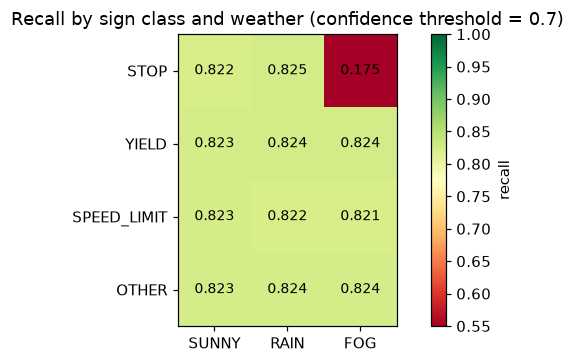

In [6]:
pivot = recall_by_class_weather.pivot(on="weather", index="actual_class", values="recall").sort(
    "actual_class"
)
matrix = pivot.drop("actual_class").to_numpy()
row_labels = [CLASS_NAMES[c] for c in pivot["actual_class"].to_list()]
col_labels = [WEATHER_NAMES[c] for c in (0, 1, 2)]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
image = ax.imshow(matrix, cmap="RdYlGn", vmin=0.55, vmax=1.0)
ax.set_xticks(range(len(col_labels)), col_labels)
ax.set_yticks(range(len(row_labels)), row_labels)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="recall")
ax.set_title("Recall by sign class and weather (confidence threshold = 0.7)")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_recall_by_class_weather.png")
plt.show()

## 4. Confidence threshold sweep

How do precision and recall trade off as we move the decision threshold?
Each point is the full 2.6M-sign dataset re-evaluated at a given threshold.

In [7]:
thresholds = np.round(np.arange(0.4, 0.951, 0.05), 3)
sweep_rows = []
for threshold in thresholds:
    effective = (
        pl.when(pl.col("confidence") >= threshold).then(pl.col("predicted_class")).otherwise(0)
    )
    tp_t, fp_t, fn_t = signs.select(
        (effective == pl.col("actual_class")).sum().alias("tp"),
        ((effective != 0) & (effective != pl.col("actual_class"))).sum().alias("fp"),
        (effective != pl.col("actual_class")).sum().alias("fn"),
    ).row(0)
    sweep_rows.append(
        {
            "threshold": float(threshold),
            "precision": tp_t / (tp_t + fp_t),
            "recall": tp_t / (tp_t + fn_t),
            "f1": 2 * tp_t / (2 * tp_t + fp_t + fn_t),
        }
    )

sweep = pl.DataFrame(sweep_rows)
sweep

threshold,precision,recall,f1
f64,f64,f64,f64
0.4,0.975335,0.952297,0.963679
0.45,0.978385,0.952297,0.965165
0.5,0.981393,0.952297,0.966626
0.55,0.984446,0.952297,0.968105
0.6,0.987551,0.952297,0.969604
…,…,…,…
0.75,0.99566,0.680226,0.808257
0.8,1.0,0.544422,0.705017
0.85,1.0,0.408244,0.579792


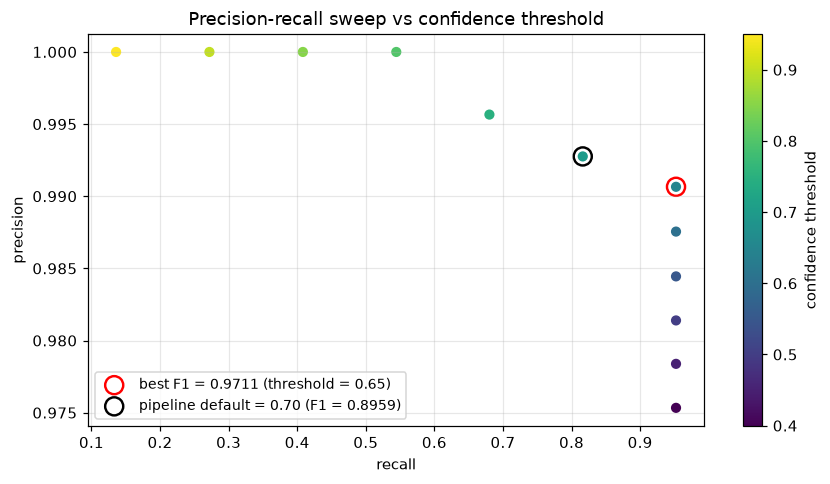

In [8]:
fig, ax = plt.subplots()
scatter = ax.scatter(
    sweep["recall"], sweep["precision"], c=sweep["threshold"], cmap="viridis", s=32
)
fig.colorbar(scatter, ax=ax, label="confidence threshold")

best = sweep.sort("f1").tail(1)
ax.scatter(
    best["recall"],
    best["precision"],
    facecolors="none",
    edgecolors="red",
    s=140,
    linewidths=1.6,
    label=f"best F1 = {best['f1'][0]:.4f} (threshold = {best['threshold'][0]:.2f})",
)

current = sweep.filter((pl.col("threshold") - 0.7).abs() < 1e-9)
ax.scatter(
    current["recall"],
    current["precision"],
    facecolors="none",
    edgecolors="black",
    s=140,
    linewidths=1.6,
    label=f"pipeline default = 0.70 (F1 = {current['f1'][0]:.4f})",
)

ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall sweep vs confidence threshold")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_precision_recall_sweep.png")
plt.show()

## 5. Safety: critical failures

Reading the aggregated report straight from the BI layer
(`data/outputs/redash_db.sqlite`) produced by the `duckdb_bridge` asset.

In [9]:
import sqlite3

con = sqlite3.connect(ROOT / "data/outputs/redash_db.sqlite")
report = pl.read_database("SELECT * FROM kpi_report", con)
con.close()

report

weather_label,weather,total_frames,tp,tn,fp,fn,critical_failures,precision,recall,f1
str,i64,i64,str,str,str,str,str,f64,f64,f64
"""SUNNY""",0,3500259,"""1438861""","""1737771""","""24348""","""309686""","""0""",0.9834,0.8229,0.896
"""RAIN""",1,999653,"""411303""","""495770""","""7109""","""88439""","""17448""",0.983,0.823,0.8959
"""FOG""",2,500088,"""189197""","""248162""","""3473""","""60753""","""25163""",0.982,0.7569,0.8549
"""ALL""",null,5000000,"""2039361""","""2481703""","""34930""","""458878""","""42611""",0.9832,0.8163,0.892


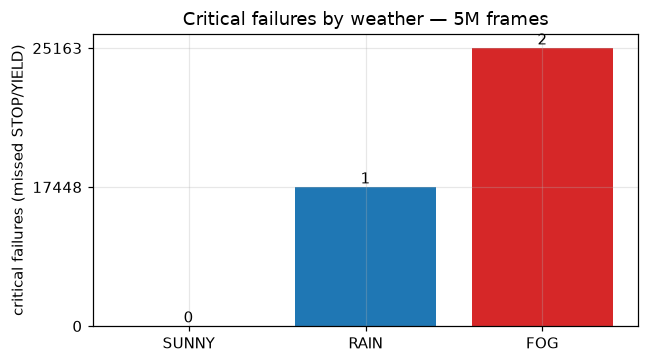

In [10]:
weather_rows = report.filter(pl.col("weather").is_not_null())

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(
    weather_rows["weather_label"].to_list(),
    weather_rows["critical_failures"].to_list(),
    color=["#2ca02c", "#1f77b4", "#d62728"],
)
ax.bar_label(bars, fmt="%d")
ax.set_ylabel("critical failures (missed STOP/YIELD)")
ax.set_title("Critical failures by weather — 5M frames")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_critical_failures.png")
plt.show()

## 6. Key findings

- **Overall (5M frames): precision 0.9832, recall 0.8163, F1 0.892** — with the
  effective-prediction rule the pipeline is deliberately conservative.
- **Fog destroys STOP recall: 0.175 vs ~0.82 in sunny weather.** Other classes
  are basically weather-invariant (~0.82), matching the injected failure mode
  (80% of STOP signs missed in fog).
- **42,611 critical failures (missed STOP/YIELD in adverse weather), zero in
  sunny conditions** — every single one happens in rain or fog.
- **The F1-optimal threshold for this synthetic model is 0.60 (F1 0.970)**, not
  the pipeline default 0.70 — the sweep turns the confidence threshold from a
  hidden constant into an explicit, measurable policy decision (a one-line change).
- Data is deterministic (generator `SEED=42`), so every number above is
  reproducible with `uv run python demo_run.py`.